In [2]:
# --- Install dependencies and detect the runtime ---
from pathlib import Path

try:
    import google.colab  # noqa: F401  (only importable inside Colab)
    IN_COLAB = True
    BASE_PATH = Path("/content")          # the folder shown in the Colab sidebar
except ImportError:
    IN_COLAB = False
    BASE_PATH = Path(".").resolve()

# `pnpl` is pinned to the competition (`refactor`) branch. The other packages are
# standard. `-q` keeps the output short.
%pip install -q --upgrade matplotlib scikit-learn lightning tensorboard pnpl
print("Running in Colab :", IN_COLAB)
print("Base path        :", BASE_PATH)


Running in Colab : True
Base path        : /content


In [3]:
# --- Confirm the key pieces are importable and pick a device ---
import sys
from pathlib import Path

import torch
import pnpl
from pnpl.datasets import LibriBrainWord  # MEG windows aligned to word onsets

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Python :", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("pnpl   :", Path(pnpl.__file__).resolve().parent)
print("Device :", DEVICE)
if DEVICE == "cpu":
    print("\n(No GPU detected. Training will work but be slower. In Colab: "
          "Runtime -> Change runtime type -> T4 GPU.)")


Python : 3.13.15
PyTorch: 2.11.0+cu128
pnpl   : /usr/local/lib/python3.13/dist-packages/pnpl
Device : cuda


In [4]:
# --- Configuration shared across the notebook ---
# Run keys are (subject, session, task, run) tuples. Subject 0 is the deep
# subject; Sherlock1 sessions 1-10 use run "1". We take a small subset.
TMIN, TMAX, SFREQ = 0.0, 1.0, 250

TRAIN_RUNS = [("0", str(s), "Sherlock1", "1") for s in range(1, 5)]   # sessions 1-4
VAL_RUNS   = [("0", "5", "Sherlock1", "1")]                            # session 5
TEST_RUNS  = [("0", "6", "Sherlock1", "1")]                            # session 6

DATA_PATH = BASE_PATH / "data" / "libribrain_word"

print("Expected time samples per window:", int((TMAX - TMIN) * SFREQ))
print("Train runs:", TRAIN_RUNS)
print("Val run   :", VAL_RUNS)
print("Test run  :", TEST_RUNS)


Expected time samples per window: 250
Train runs: [('0', '1', 'Sherlock1', '1'), ('0', '2', 'Sherlock1', '1'), ('0', '3', 'Sherlock1', '1'), ('0', '4', 'Sherlock1', '1')]
Val run   : [('0', '5', 'Sherlock1', '1')]
Test run  : [('0', '6', 'Sherlock1', '1')]


In [ ]:
# --- Load one session and inspect a single example ---
from pnpl.datasets import LibriBrainWord

one_run = LibriBrainWord(
    data_path=str(DATA_PATH),
    include_run_keys=[TRAIN_RUNS[0]],
    tmin=TMIN,
    tmax=TMAX,
    standardize=False,     # show raw-ish values for this first look
    include_info=True,     # also return a dict with the word string, onset, etc.
    preload_files=False,   # download lazily instead of all-at-once
)

meg, label_id, info = one_run[0]
word = one_run.id_to_word[int(label_id)]

print("Examples in this session :", len(one_run))
print("MEG window shape         :", tuple(meg.shape), "  (sensors, time)")
print("Label id (within session) + which word it represents:", int(label_id), "->", repr(word))
print("Info for this example    :", info)


Examples in this session : 2836
MEG window shape         : (306, 250)   (sensors, time)
Label id (within session) + which word it represents: 0 -> 'A'
Info for this example    : {'dataset': 'libribrain2025', 'subject': '0', 'session': '1', 'task': 'Sherlock1', 'run': '1', 'onset': tensor(30.0860)}


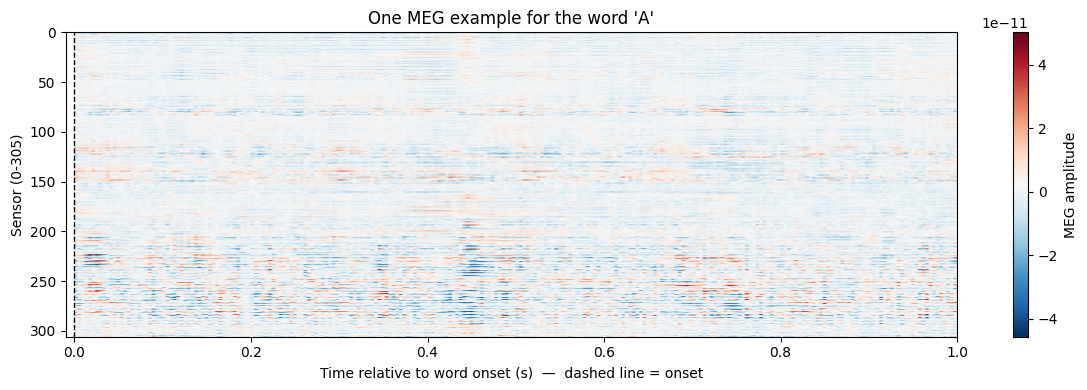

In [9]:
# --- Visualise the MEG window for a single word ---
import matplotlib.pyplot as plt

meg, label_id, info = one_run[0]
word = one_run.id_to_word[int(label_id)]

plt.figure(figsize=(12, 4))
plt.imshow(meg.numpy(), aspect="auto", cmap="RdBu_r",
           extent=[TMIN, TMAX, meg.shape[0], 0])
plt.axvline(0.0, color="k", lw=1, ls="--")  # word onset
plt.xlim(-0.01, 1.0)
plt.colorbar(label="MEG amplitude")
plt.xlabel("Time relative to word onset (s)  —  dashed line = onset")
plt.ylabel("Sensor (0-305)")
plt.title("One MEG example for the word " + repr(word))
plt.tight_layout()
plt.show()


In [10]:
# --- Read the raw event file for one session ---
import pandas as pd

events_path = one_run.get_events_path(*TRAIN_RUNS[0])
events = pd.read_csv(events_path, sep="\t")
word_rows = events[events["kind"] == "word"].copy()

print("Event file:", events_path)
print("Total word events in this session:", len(word_rows))
word_rows.head(10)


Event file: /content/data/libribrain_word/Sherlock1/derivatives/events/sub-0_ses-1_task-Sherlock1_run-1_events.tsv
Total word events in this session: 2836


,idx,wavile,kind,segment,sentenceidx,wordidx,phonemeidx,timemeg,timeds,timechapter,timesentence,duration
1,2,segments/,word,A,0.0,0.0,NaN,30.086,30.084,1.298,0.11,0.10
3,4,segments/,word,Study,0.0,1.0,NaN,30.186,30.184,1.398,0.21,0.37
9,10,segments/,word,in,0.0,2.0,NaN,30.556,30.556,1.768,0.58,0.14
12,13,segments/,word,Scarlet,0.0,3.0,NaN,30.696,30.696,1.908,0.72,0.59
20,21,segments/,word,by,0.0,4.0,NaN,31.466,31.464,2.678,1.49,0.36
23,24,segments/,word,Sir,0.0,5.0,NaN,31.836,31.836,3.048,1.86,0.21
26,27,segments/,word,Arthur,0.0,6.0,NaN,32.056,32.056,3.268,2.08,0.33
31,32,segments/,word,Conan,0.0,7.0,NaN,32.386,32.384,3.598,2.41,0.37
37,38,segments/,word,Doyle,0.0,8.0,NaN,32.756,32.756,3.968,2.78,0.20
42,43,segments/,word,This,1.0,0.0,NaN,33.882,33.884,5.070,0.13,0.09


Unique word types in this session: 981

20 most frequent words:
segment
the     119
i       101
a        91
to       80
and      78
of       67
he       54
in       51
you      41
my       35
as       34
it       33
with     33
is       32
that     29
his      28
for      27
at       27
was      26
me       24
Name: count, dtype: int64


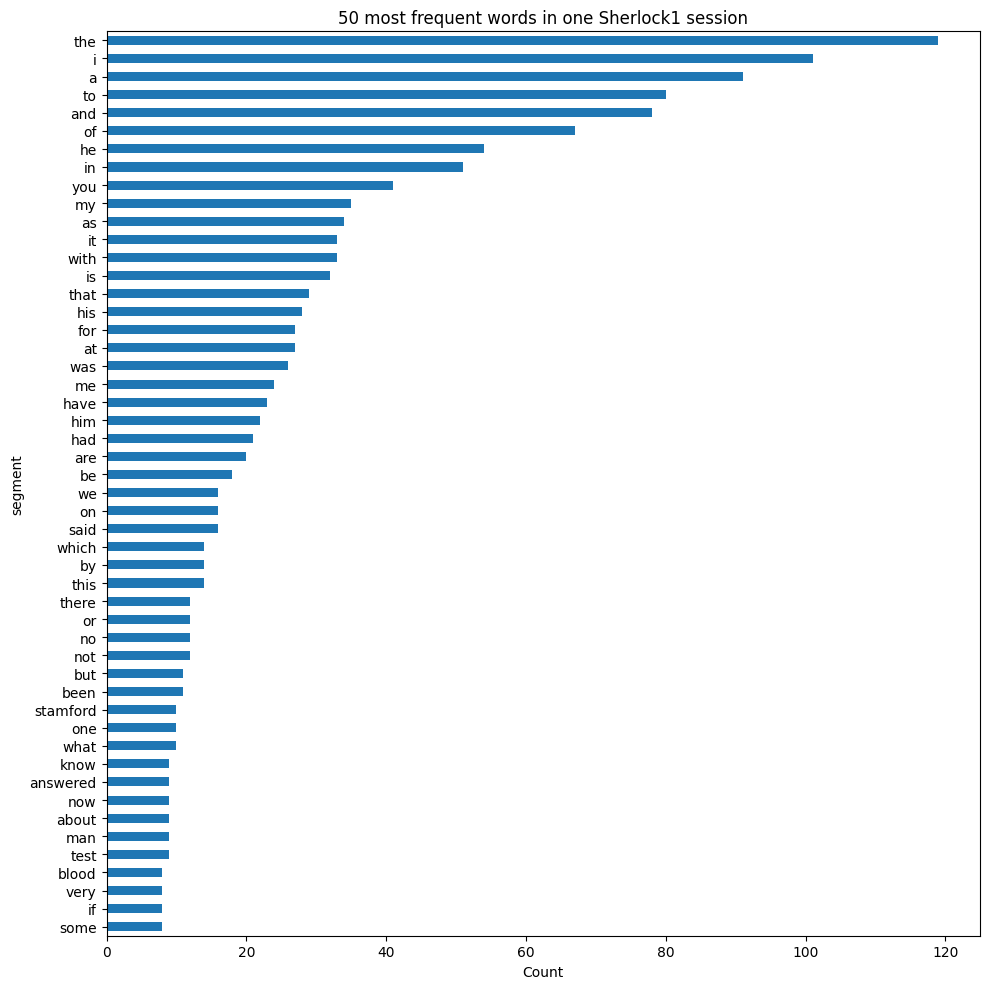

In [11]:
# --- The long tail: a few words dominate ---
import matplotlib.pyplot as plt
import pandas as pd

counts = (word_rows["segment"].astype(str).str.strip().str.lower()
          .value_counts())

print("Unique word types in this session:", len(counts))
print("\n20 most frequent words:")
print(counts.head(20))

counts.head(50)[::-1].plot.barh(figsize=(10, 10))
plt.title("50 most frequent words in one Sherlock1 session")
plt.xlabel("Count")
plt.tight_layout()
plt.show()


In [12]:
# --- Load the official vocabularies straight from the installed package ---
from pnpl.competition import load_vocabulary

VOCAB = load_vocabulary("primary")      # the 50 competition words, in order
MOSES = load_vocabulary("moses")        # the 50 Moses words (secondary metric)

print("Competition vocabulary size:", len(VOCAB))
print(VOCAB)
print("\nMoses-50 (secondary):")
print(MOSES)


Competition vocabulary size: 50
['is', 'the', 'a', 'to', 'it', 'i', 'not', 'was', 'we', 'be', 'he', 'that', 'have', 'this', 'they', 'of', 'there', 'and', 'are', 'in', 'but', 'will', 'so', 'all', 'my', 'for', 'she', 'were', 'any', 'really', 'at', 'out', 'our', 'am', 'it’s', 'had', 'him', 'an', 'very', 'has', 'do', 'can', 'time', 'think', 'good', 'always', 'new', 'people', 'as', 'on']

Moses-50 (secondary):
['am', 'are', 'bad', 'bring', 'clean', 'closer', 'comfortable', 'coming', 'computer', 'do', 'faith', 'family', 'feel', 'glasses', 'going', 'good', 'goodbye', 'have', 'hello', 'help', 'here', 'hope', 'how', 'hungry', 'i', 'is', 'it', 'like', 'music', 'my', 'need', 'no', 'not', 'nurse', 'okay', 'outside', 'please', 'right', 'success', 'tell', 'that', 'they', 'thirsty', 'tired', 'up', 'very', 'what', 'where', 'yes', 'you']


In [13]:
# --- Build a normalisation-robust lookup from word string -> vocab id ---
def normalize_word(w):
    # lowercase, strip whitespace, and unify the curly apostrophe (it’s -> it's)
    return str(w).strip().lower().replace("’", "'")

VOCAB_TO_ID = {normalize_word(w): i for i, w in enumerate(VOCAB)}

# How much of this one session is in-vocabulary?
in_vocab = sum(normalize_word(s[5]) in VOCAB_TO_ID for s in one_run.samples)
print("In-vocabulary examples in this session: "
      "{} / {} ({:.0%})".format(in_vocab, len(one_run.samples),
                                in_vocab / len(one_run.samples)))


In-vocabulary examples in this session: 1158 / 2836 (41%)


In [14]:
# --- A thin wrapper that maps each example to the 50-word competition vocab ---
import torch
from torch.utils.data import Dataset
from pnpl.datasets import LibriBrainWord


def make_word_dataset(run_keys):
    # standardize=True z-scores each channel; clipping tames outliers.
    return LibriBrainWord(
        data_path=str(DATA_PATH),
        include_run_keys=list(run_keys),
        tmin=TMIN, tmax=TMAX,
        standardize=True,
        include_info=False,
        preload_files=False,
    )


class CompetitionVocabDataset(Dataset):
    """Filter a LibriBrainWord dataset to the 50 competition words."""

    def __init__(self, base):
        self.base = base
        # Pre-compute which base indices are in-vocabulary and their vocab id.
        self.keep = []
        for i, sample in enumerate(base.samples):
            vid = VOCAB_TO_ID.get(normalize_word(sample[5]))
            if vid is not None:
                self.keep.append((i, vid))

    def __len__(self):
        return len(self.keep)

    def __getitem__(self, idx):
        base_idx, vocab_id = self.keep[idx]
        meg = self.base[base_idx][0].float()
        return meg, torch.tensor(vocab_id, dtype=torch.long)


train_ds = CompetitionVocabDataset(make_word_dataset(TRAIN_RUNS))
val_ds   = CompetitionVocabDataset(make_word_dataset(VAL_RUNS))
test_ds  = CompetitionVocabDataset(make_word_dataset(TEST_RUNS))

print("Train / val / test in-vocab examples: "
      "{} / {} / {}".format(len(train_ds), len(val_ds), len(test_ds)))


Sherlock1/derivatives/serialised/sub-0_s(…): reconstructing file:   0%|          |  0.00B /  429MB            

Sherlock1/derivatives/serialised/sub-0_s(…): downloading bytes:           |  0.00B            

Sherlock1/derivatives/serialised/sub-0_s(…): reconstructing file:   0%|          |  0.00B /  461MB            

Sherlock1/derivatives/serialised/sub-0_s(…): downloading bytes:           |  0.00B            

Sherlock1/derivatives/serialised/sub-0_s(…): reconstructing file:   0%|          |  0.00B /  300MB            

Sherlock1/derivatives/serialised/sub-0_s(…): downloading bytes:           |  0.00B            

... (6 outputs left out)

Sherlock1/derivatives/serialised/sub-0_s(…): reconstructing file:   0%|          |  0.00B /  400MB            

Sherlock1/derivatives/serialised/sub-0_s(…): downloading bytes:           |  0.00B            

(…)-0_ses-6_task-Sherlock1_run-1_events.tsv:   0%|          | 0.00/1.24M [00:00<?, ?B/s]

Train / val / test in-vocab examples: 5222 / 1080 / 1265


In [15]:
# --- Wrap the datasets in DataLoaders ---
from torch.utils.data import DataLoader

BATCH_SIZE = 64
NUM_WORKERS = 2 if IN_COLAB else 0

# drop_last=True on the training loader avoids a final size-1 batch, which
# BatchNorm cannot handle in train mode.
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, drop_last=True)
val_loader   = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS)
test_loader  = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS)

xb, yb = next(iter(train_loader))
print("Batch MEG shape  :", tuple(xb.shape), "  (batch, sensors, time)")
print("Batch label shape:", tuple(yb.shape))
print("First labels     :", yb[:8].tolist(),
      "->", [VOCAB[i] for i in yb[:8].tolist()])


Batch MEG shape  : (64, 306, 250)   (batch, sensors, time)
Batch label shape: (64,)
First labels     : [15, 2, 1, 1, 17, 17, 17, 1] -> ['of', 'a', 'the', 'the', 'and', 'and', 'and', 'the']


In [16]:
# --- Define the classifier ---
import torch.nn as nn


class SimpleWordCNN(nn.Module):
    def __init__(self, n_channels, n_classes):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv1d(n_channels, 128, kernel_size=9, padding=4),
            nn.BatchNorm1d(128), nn.GELU(), nn.MaxPool1d(4),
            nn.Conv1d(128, 256, kernel_size=9, padding=4),
            nn.BatchNorm1d(256), nn.GELU(), nn.MaxPool1d(4),
            nn.Conv1d(256, 256, kernel_size=5, padding=2),
            nn.GELU(), nn.AdaptiveAvgPool1d(1),   # -> (batch, 256, 1)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Dropout(0.3), nn.Linear(256, n_classes),
        )

    def forward(self, x):
        return self.classifier(self.encoder(x))


# Quick shape sanity check on one batch (no training yet).
_probe = SimpleWordCNN(n_channels=xb.shape[1], n_classes=len(VOCAB))
print("Logits for one batch:", tuple(_probe(xb).shape), "(batch, 50)")


Logits for one batch: (64, 50) (batch, 50)


In [67]:
# --- The official-style metric, implemented once and reused ---
import torch


def balanced_topk_accuracy(logits, labels, k, n_classes):
    # Macro-averaged Recall@k: average the per-class top-k hit rate over all
    # classes that appear in `labels`.
    k = min(k, logits.shape[1])
    topk = logits.topk(k, dim=1).indices                  # (N, k)
    hit = (topk == labels.unsqueeze(1)).any(dim=1).float()  # (N,)
    recalls = []
    for c in range(n_classes):
        mask = labels == c
        if mask.any():
            recalls.append(hit[mask].mean())
    if not recalls:
        return 0.0
    return float(torch.stack(recalls).mean())


# Sanity check: a random classifier should score ~k/n_classes on BAcc@k.
torch.manual_seed(0)
rnd_logits = torch.randn(2000, len(VOCAB))
rnd_labels = torch.randint(0, len(VOCAB), (2000,))
print("Random BAcc@10:", round(balanced_topk_accuracy(rnd_logits, rnd_labels, 10, len(VOCAB)), 3),
      "(expected ~0.20)")
print("Random BAcc@1 :", round(balanced_topk_accuracy(rnd_logits, rnd_labels, 1, len(VOCAB)), 3),
      "(expected ~0.02)")


Random BAcc@10: 0.214 (expected ~0.20)
Random BAcc@1 : 0.023 (expected ~0.02)


In [68]:
# --- Lightning module wrapping the CNN + the competition metric ---
import lightning as L
import torch
import torch.nn as nn


class LitWordClassifier(L.LightningModule):
    def __init__(self, n_channels, n_classes, lr=1e-3):
        super().__init__()
        self.save_hyperparameters()
        self.model = SimpleWordCNN(n_channels, n_classes)
        self.loss_fn = nn.CrossEntropyLoss()
        self._val_logits, self._val_labels = [], []

    def forward(self, x):
        return self.model(x)

    def training_step(self, batch, _):
        x, y = batch
        loss = self.loss_fn(self(x), y)
        self.log("train_loss", loss, on_step=False, on_epoch=True,
                 prog_bar=True, batch_size=x.shape[0])
        return loss

    def validation_step(self, batch, _):
        x, y = batch
        logits = self(x)
        self.log("val_loss", self.loss_fn(logits, y), on_step=False,
                 on_epoch=True, prog_bar=True, batch_size=x.shape[0])
        self._val_logits.append(logits.detach().cpu())
        self._val_labels.append(y.detach().cpu())

    def on_validation_epoch_end(self):
        if not self._val_logits:
            return
        logits = torch.cat(self._val_logits)
        labels = torch.cat(self._val_labels)
        n = self.hparams.n_classes
        self.log("val_bacc10", balanced_topk_accuracy(logits, labels, 10, n), prog_bar=True)
        self.log("val_bacc1", balanced_topk_accuracy(logits, labels, 1, n), prog_bar=True)
        self._val_logits.clear()
        self._val_labels.clear()

    def configure_optimizers(self):
        return torch.optim.Adam(self.parameters(), lr=self.hparams.lr)


model = LitWordClassifier(n_channels=train_ds[0][0].shape[0], n_classes=len(VOCAB))
print(model.model)


SimpleWordCNN(
  (encoder): Sequential(
    (0): Conv1d(306, 128, kernel_size=(9,), stride=(1,), padding=(4,))
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): GELU(approximate='none')
    (3): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
    (4): Conv1d(128, 256, kernel_size=(9,), stride=(1,), padding=(4,))
    (5): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): GELU(approximate='none')
    (7): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
    (8): Conv1d(256, 256, kernel_size=(5,), stride=(1,), padding=(2,))
    (9): GELU(approximate='none')
    (10): AdaptiveAvgPool1d(output_size=1)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.3, inplace=False)
    (2): Linear(in_features=256, out_features=50, bias=True)
  )
)


In [69]:
# --- Train ---
import lightning as L
from lightning.pytorch.callbacks import EarlyStopping
from lightning.pytorch.loggers import CSVLogger

EPOCHS = 1

csv_logger = CSVLogger(save_dir=str(BASE_PATH / "lightning_logs"), name="word_intro")

trainer = L.Trainer(
    max_epochs=EPOCHS,
    accelerator="auto",
    devices=1,
    logger=csv_logger,
    callbacks=[EarlyStopping(monitor="val_bacc10", mode="max", patience=5)],
    enable_checkpointing=False,
    log_every_n_steps=5,
)

trainer.fit(model, train_loader, val_loader)
print("\nLogged metrics ->", csv_logger.log_dir)


INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


┏━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name    ┃ Type             ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model   │ SimpleWordCNN    │  989 K │ train │     0 │
│ 1 │ loss_fn │ CrossEntropyLoss │      0 │ train │     0 │
└───┴─────────┴──────────────────┴────────┴───────┴───────┘

Trainable params: 989 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 989 K                                                                                                
Total estimated model params size (MB): 3.957                                                                      
Modules in train mode: 18                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

INFO: `Trainer.fit` stopped: `max_epochs=1` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=1` reached.



Logged metrics -> /content/lightning_logs/word_intro/version_0


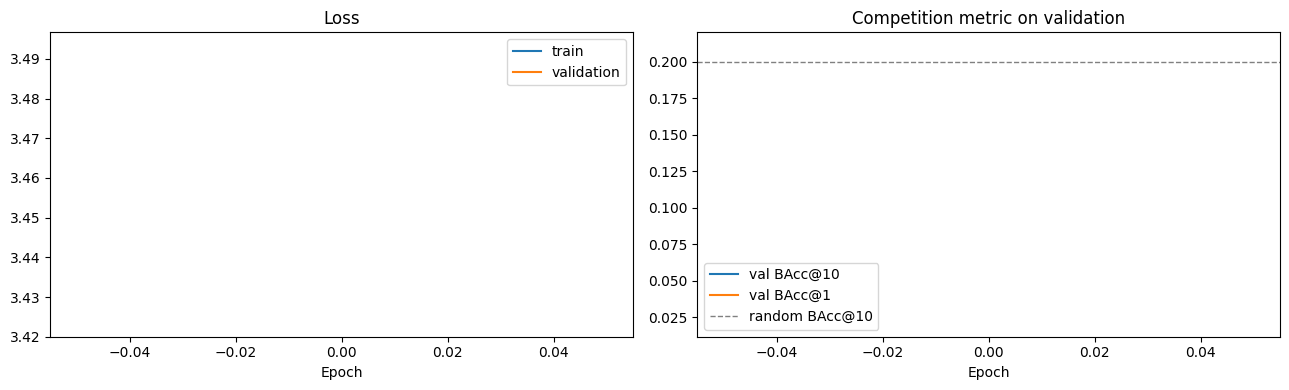

In [70]:
# --- Plot the learning curves from the CSV log ---
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

metrics = pd.read_csv(Path(csv_logger.log_dir) / "metrics.csv")

# One row per epoch with the last value logged for each metric.
per_epoch = metrics.groupby("epoch").last(numeric_only=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
if "train_loss" in per_epoch:
    ax1.plot(per_epoch.index, per_epoch["train_loss"], label="train")
if "val_loss" in per_epoch:
    ax1.plot(per_epoch.index, per_epoch["val_loss"], label="validation")
ax1.set_title("Loss"); ax1.set_xlabel("Epoch"); ax1.legend()

if "val_bacc10" in per_epoch:
    ax2.plot(per_epoch.index, per_epoch["val_bacc10"], label="val BAcc@10")
if "val_bacc1" in per_epoch:
    ax2.plot(per_epoch.index, per_epoch["val_bacc1"], label="val BAcc@1")
ax2.axhline(0.20, color="grey", ls="--", lw=1, label="random BAcc@10")
ax2.set_title("Competition metric on validation"); ax2.set_xlabel("Epoch"); ax2.legend()
plt.tight_layout(); plt.show()


In [71]:
# --- Run the trained model over the test set ---
import torch

model.eval().to(DEVICE)
all_logits, all_labels = [], []
with torch.no_grad():
    for x, y in test_loader:
        all_logits.append(model(x.to(DEVICE)).cpu())
        all_labels.append(y)
all_logits = torch.cat(all_logits)
all_labels = torch.cat(all_labels)

n = len(VOCAB)
print("Test BAcc@10:", round(balanced_topk_accuracy(all_logits, all_labels, 10, n), 3),
      " (random ~0.20)")
print("Test BAcc@1 :", round(balanced_topk_accuracy(all_logits, all_labels, 1, n), 3),
      " (random ~0.02)")


Test BAcc@10: 0.199  (random ~0.20)
Test BAcc@1 : 0.02  (random ~0.02)


In [72]:
# --- A few individual predictions, with the model's top-5 shortlist ---
import pandas as pd

top5 = all_logits.topk(5, dim=1).indices
rows = []
for i in range(min(12, len(all_labels))):
    rows.append({
        "true_word": VOCAB[int(all_labels[i])],
        "predicted": VOCAB[int(top5[i, 0])],
        "top5_shortlist": [VOCAB[int(j)] for j in top5[i]],
    })
pd.DataFrame(rows)


,true_word,predicted,top5_shortlist
0,of,the,"[the, of, i, a, in]"
1,a,the,"[the, of, i, a, in]"
2,in,the,"[the, of, a, i, and]"
3,this,the,"[the, of, i, a, in]"
4,is,the,"[the, of, a, i, to]"
5,in,the,"[the, of, a, i, to]"
6,the,the,"[the, of, a, i, to]"
7,he,the,"[the, a, and, i, of]"
8,can,the,"[the, a, and, i, of]"
9,do,the,"[the, a, and, i, of]"


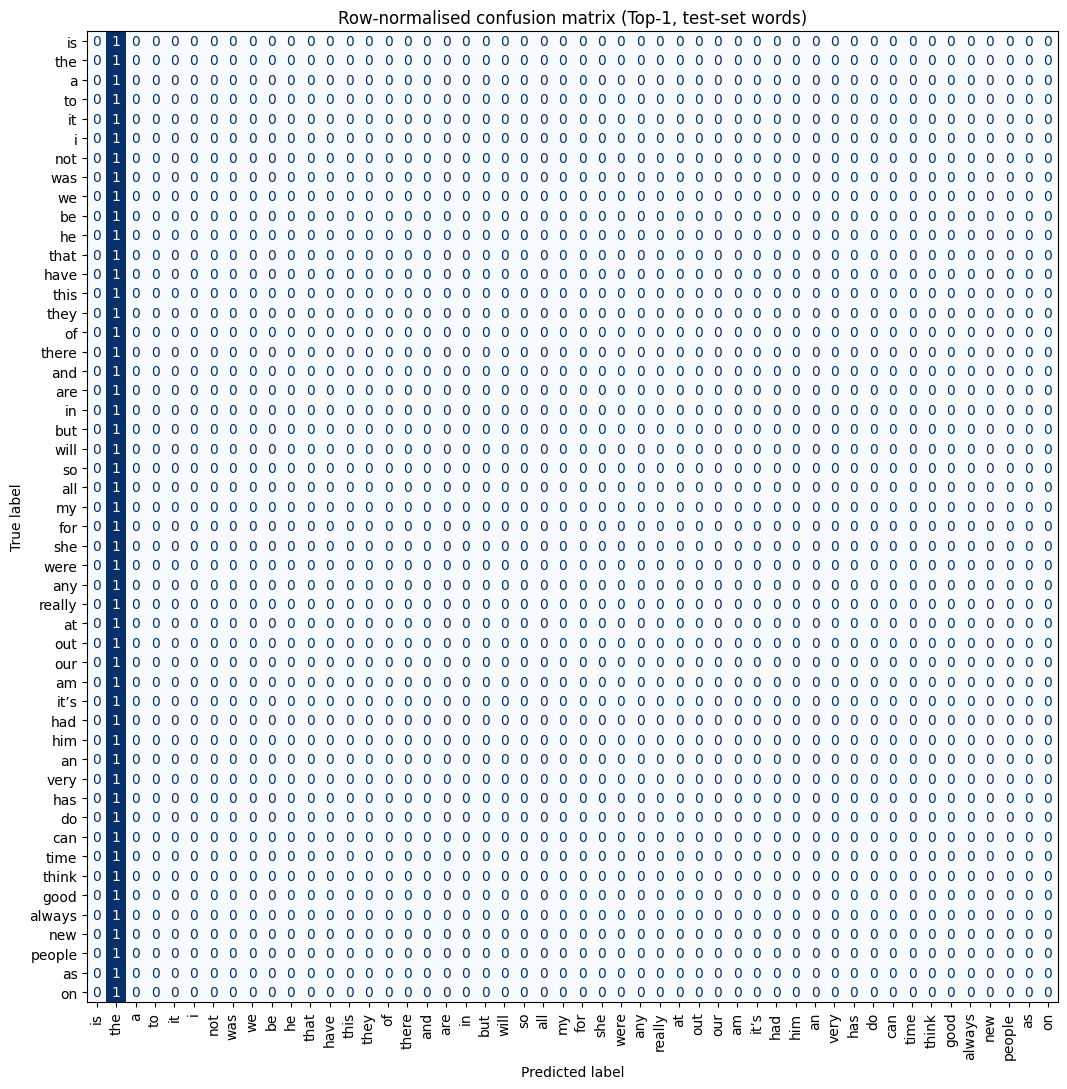

In [73]:
# --- Row-normalised confusion matrix (Top-1) over the 50 words ---
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

pred1 = all_logits.argmax(dim=1).numpy()
true = all_labels.numpy()

# Restrict to words that actually occur in the test set to keep the plot legible.
present = sorted(set(true.tolist()))
labels_present = [VOCAB[i] for i in present]
cm = confusion_matrix(true, pred1, labels=present, normalize="true")

fig, ax = plt.subplots(figsize=(11, 11))
ConfusionMatrixDisplay(cm, display_labels=labels_present).plot(
    ax=ax, xticks_rotation=90, colorbar=False, cmap="Blues")
ax.set_title("Row-normalised confusion matrix (Top-1, test-set words)")
plt.tight_layout(); plt.show()
